### A Python program that implements the Committee Machine with Training Algorithms (CMTA) 
### The program predicts Normalized Oil Content (NOC) from Well Log Data
### This implementation will include the five neural network training algorithms and genetic algorithm optimization

#### Keith R. Holdaway FGS

Dataset shape: (231, 5)
NOC range: [0.000, 1.000]
Training data: 155 samples
Validation data: 39 samples
Testing data: 37 samples

Training individual neural network models...
Training LM model...
LM Model - MSE: 0.0366, R²: 0.8157
Training BR model...
BR Model - MSE: 0.0343, R²: 0.8269
Training GD model...
GD Model - MSE: 0.0466, R²: 0.7652
Training OSS model...
OSS Model - MSE: 0.0323, R²: 0.8372
Training RP model...
RP Model - MSE: 0.0236, R²: 0.8808

Optimizing committee weights with genetic algorithm...
Generation 0: Best Fitness = -0.022489
Generation 10: Best Fitness = -0.021932
Generation 20: Best Fitness = -0.021924
Generation 30: Best Fitness = -0.021924
Generation 40: Best Fitness = -0.021924
Optimized weights:
LM: 0.0009
BR: 0.1822
GD: 0.0220
OSS: 0.2601
RP: 0.5347

Evaluating on testing data...
LM   - MSE: 0.031277, R²: 0.7701
BR   - MSE: 0.026827, R²: 0.8028
GD   - MSE: 0.019982, R²: 0.8531
OSS  - MSE: 0.028903, R²: 0.7876
RP   - MSE: 0.022628, R²: 0.8337

CMTA - MSE: 0.0

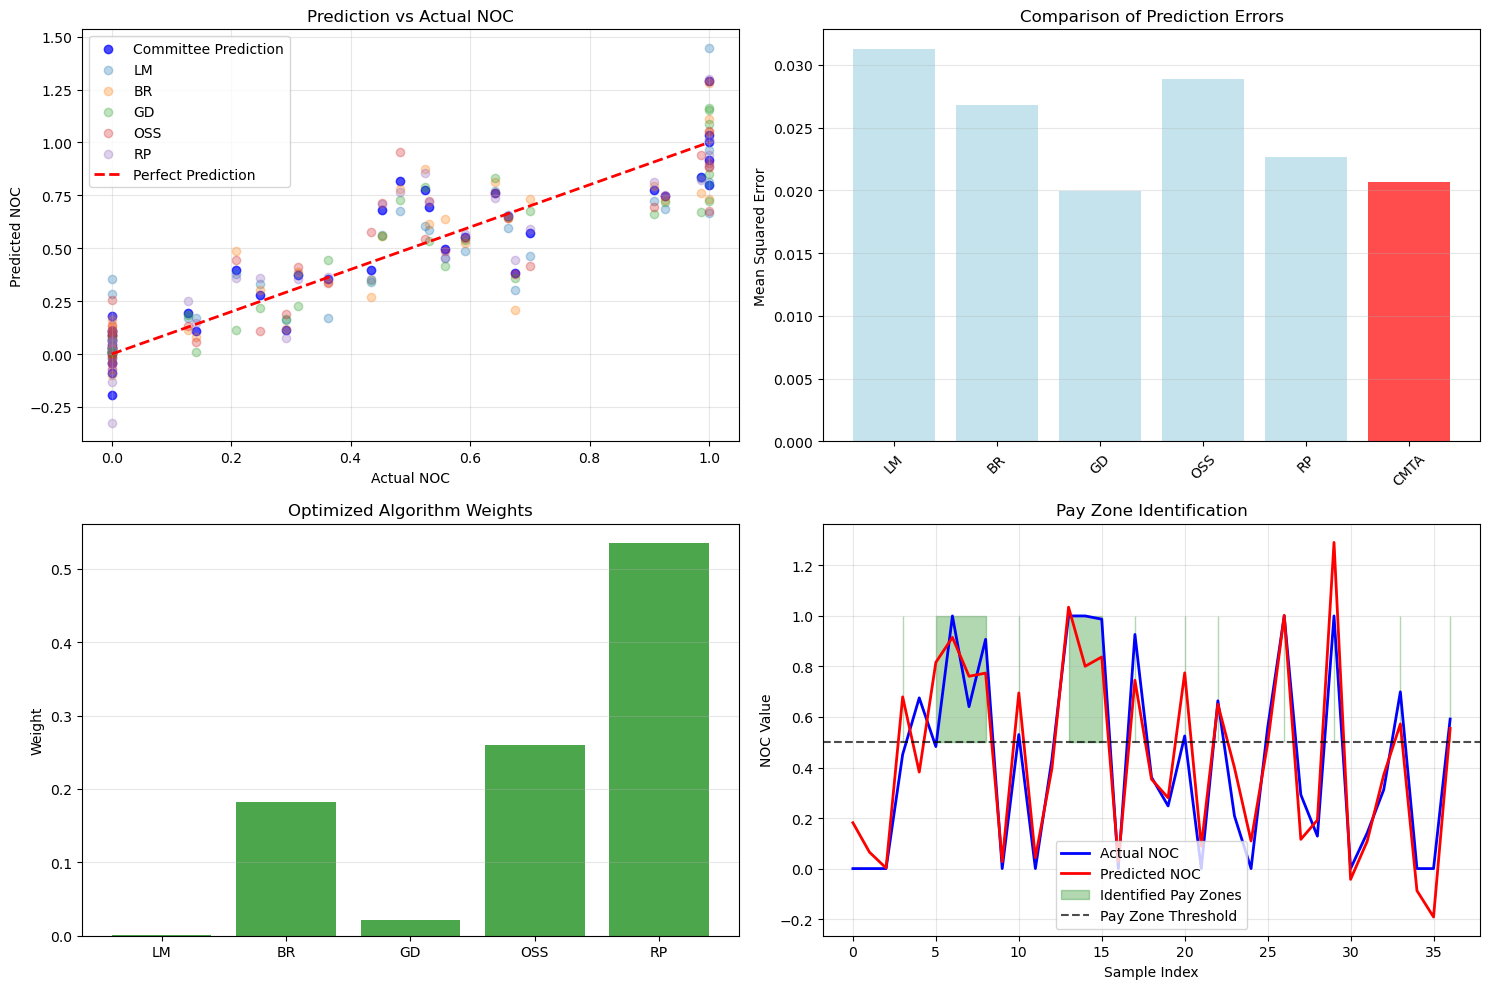

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD, RMSprop
from tensorflow.keras.regularizers import l2

class GeneticAlgorithmOptimizer:
    """Genetic Algorithm implementation for weight optimization"""
    
    def __init__(self, n_individuals, n_genes, fitness_function, 
                 mutation_rate=0.1, crossover_rate=0.8, elitism_count=2):
        self.n_individuals = n_individuals
        self.n_genes = n_genes
        self.fitness_function = fitness_function
        self.mutation_rate = mutation_rate
        self.crossover_rate = crossover_rate
        self.elitism_count = elitism_count
        
    def initialize_population(self):
        """Initialize random population with normalized weights"""
        population = np.random.uniform(0, 1, (self.n_individuals, self.n_genes))
        # Normalize each individual to sum to 1
        population = population / population.sum(axis=1, keepdims=True)
        return population
    
    def evaluate_fitness(self, population):
        """Evaluate fitness for each individual in population"""
        fitness_scores = np.zeros(self.n_individuals)
        for i, individual in enumerate(population):
            fitness_scores[i] = self.fitness_function(individual)
        return fitness_scores
    
    def select_parents(self, population, fitness_scores):
        """Tournament selection"""
        selected_indices = []
        for _ in range(self.n_individuals):
            # Tournament of size 3
            contestants = np.random.choice(len(population), 3, replace=False)
            winner = contestants[np.argmax(fitness_scores[contestants])]
            selected_indices.append(winner)
        return population[selected_indices]
    
    def crossover(self, parents):
        """Single-point crossover"""
        offspring = []
        for i in range(0, len(parents), 2):
            if i + 1 < len(parents):
                parent1 = parents[i]
                parent2 = parents[i + 1]
                
                if np.random.random() < self.crossover_rate:
                    crossover_point = np.random.randint(1, self.n_genes)
                    child1 = np.concatenate([parent1[:crossover_point], parent2[crossover_point:]])
                    child2 = np.concatenate([parent2[:crossover_point], parent1[crossover_point:]])
                else:
                    child1, child2 = parent1.copy(), parent2.copy()
                
                offspring.extend([child1, child2])
        return np.array(offspring)
    
    def mutate(self, population):
        """Random mutation"""
        mutated_population = population.copy()
        for i in range(len(mutated_population)):
            if np.random.random() < self.mutation_rate:
                mutation_point = np.random.randint(self.n_genes)
                mutated_population[i][mutation_point] = np.random.uniform(0, 1)
                # Renormalize after mutation
                mutated_population[i] = mutated_population[i] / mutated_population[i].sum()
        return mutated_population
    
    def apply_elitism(self, old_population, new_population, old_fitness):
        """Preserve best individuals"""
        elite_indices = np.argsort(old_fitness)[-self.elitism_count:]
        new_population[:self.elitism_count] = old_population[elite_indices]
        return new_population
    
    def optimize(self, generations=100):
        """Main optimization loop"""
        population = self.initialize_population()
        best_fitness_history = []
        best_individual_history = []
        
        for generation in range(generations):
            # Evaluate fitness
            fitness_scores = self.evaluate_fitness(population)
            
            # Track best individual
            best_idx = np.argmax(fitness_scores)
            best_fitness = fitness_scores[best_idx]
            best_individual = population[best_idx].copy()
            
            best_fitness_history.append(best_fitness)
            best_individual_history.append(best_individual)
            
            # Selection
            selected_parents = self.select_parents(population, fitness_scores)
            
            # Crossover
            offspring = self.crossover(selected_parents)
            
            # Mutation
            mutated_offspring = self.mutate(offspring)
            
            # Elitism
            if self.elitism_count > 0:
                mutated_offspring = self.apply_elitism(
                    population, mutated_offspring, fitness_scores
                )
            
            population = mutated_offspring
            
            if generation % 10 == 0:
                print(f"Generation {generation}: Best Fitness = {best_fitness:.6f}")
        
        # Return best individual from all generations
        best_overall_idx = np.argmax(best_fitness_history)
        return best_individual_history[best_overall_idx], best_fitness_history

class CMTA_NOC_Predictor:
    def __init__(self, input_dim, hidden_layers=[10, 8, 5]):
        self.input_dim = input_dim
        self.hidden_layers = hidden_layers
        self.models = {}
        self.scalers = {}
        self.weights = None
        
    def create_model(self, algorithm_name):
        """Create neural network model with specific training algorithm"""
        model = Sequential()
        
        # Input layer - use Input layer instead of input_dim in Dense
        model.add(Input(shape=(self.input_dim,)))
        model.add(Dense(self.hidden_layers[0], 
                       activation='relu', 
                       kernel_initializer='he_normal'))
        
        # Hidden layers
        for neurons in self.hidden_layers[1:]:
            model.add(Dense(neurons, activation='relu', kernel_initializer='he_normal'))
        
        # Output layer
        model.add(Dense(1, activation='linear', kernel_initializer='he_normal'))
        
        # Configure optimizer based on algorithm
        if algorithm_name == 'LM':
            # Levenberg-Marquardt approximation
            optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
            model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
            
        elif algorithm_name == 'BR':
            # Bayesian Regularization with L2 regularization
            for i, layer in enumerate(model.layers):
                if hasattr(layer, 'kernel_regularizer'):
                    model.layers[i].kernel_regularizer = l2(0.01)
            optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
            model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
            
        elif algorithm_name == 'GD':
            # Gradient Descent with momentum
            optimizer = SGD(learning_rate=0.01, momentum=0.9)
            model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
            
        elif algorithm_name == 'OSS':
            # One Step Secant approximation
            optimizer = RMSprop(learning_rate=0.001)
            model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
            
        elif algorithm_name == 'RP':
            # Resilient Backpropagation approximation
            optimizer = RMSprop(learning_rate=0.001, rho=0.9)
            model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])
            
        return model
    
    def train_individual_models(self, X_train, y_train, X_val, y_val, epochs=100, batch_size=16):
        """Train each algorithm individually"""
        algorithms = ['LM', 'BR', 'GD', 'OSS', 'RP']
        history_dict = {}
        
        for algo in algorithms:
            print(f"Training {algo} model...")
            
            # Scale data
            X_scaler = StandardScaler()
            y_scaler = StandardScaler()
            
            X_train_scaled = X_scaler.fit_transform(X_train)
            X_val_scaled = X_scaler.transform(X_val)
            y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).flatten()
            y_val_scaled = y_scaler.transform(y_val.reshape(-1, 1)).flatten()
            
            # Store scalers
            self.scalers[algo] = {'X': X_scaler, 'y': y_scaler}
            
            # Create and train model
            model = self.create_model(algo)
            history = model.fit(
                X_train_scaled, y_train_scaled,
                validation_data=(X_val_scaled, y_val_scaled),
                epochs=epochs,
                batch_size=batch_size,
                verbose=0,
                callbacks=[tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)]
            )
            
            self.models[algo] = model
            history_dict[algo] = history
            
            # Evaluate model
            y_pred_scaled = model.predict(X_val_scaled, verbose=0)
            y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1))
            
            mse = mean_squared_error(y_val, y_pred)
            r2 = r2_score(y_val, y_pred)
            
            print(f"{algo} Model - MSE: {mse:.4f}, R²: {r2:.4f}")
        
        return history_dict
    
    def predict_individual(self, X, algorithm):
        """Make prediction using a specific algorithm"""
        if algorithm not in self.models:
            raise ValueError(f"Algorithm {algorithm} not trained")
        
        scaler = self.scalers[algorithm]
        X_scaled = scaler['X'].transform(X)
        y_pred_scaled = self.models[algorithm].predict(X_scaled, verbose=0)
        y_pred = scaler['y'].inverse_transform(y_pred_scaled.reshape(-1, 1))
        
        return y_pred.flatten()
    
    def committee_predict(self, X, weights=None):
        """Make prediction using committee machine with optional weights"""
        if weights is None:
            weights = np.ones(len(self.models)) / len(self.models)  # Equal weights
        
        predictions = []
        algorithms = list(self.models.keys())
        
        for i, algo in enumerate(algorithms):
            pred = self.predict_individual(X, algo)
            predictions.append(pred * weights[i])
        
        # Weighted average of predictions
        committee_pred = np.sum(predictions, axis=0)
        
        return committee_pred
    
    def optimize_weights_genetic(self, X_val, y_val, pop_size=50, generations=100):
        """Optimize committee weights using genetic algorithm"""
        algorithms = list(self.models.keys())
        n_algorithms = len(algorithms)
        
        # Generate individual predictions for validation set
        individual_preds = []
        for algo in algorithms:
            pred = self.predict_individual(X_val, algo)
            individual_preds.append(pred)
        
        individual_preds = np.array(individual_preds)
        
        # Fitness function: minimize MSE of committee prediction
        def fitness_function(weights):
            # Ensure weights are properly normalized
            weights = np.array(weights)
            weights = np.maximum(weights, 0)  # Ensure non-negative
            weights = weights / np.sum(weights)
            
            committee_pred = np.sum(individual_preds * weights.reshape(-1, 1), axis=0)
            mse = mean_squared_error(y_val, committee_pred)
            return -mse  # Negative because we want to minimize MSE
        
        # Initialize and run genetic algorithm
        ga_optimizer = GeneticAlgorithmOptimizer(
            n_individuals=pop_size,
            n_genes=n_algorithms,
            fitness_function=fitness_function,
            mutation_rate=0.1,
            crossover_rate=0.8,
            elitism_count=2
        )
        
        best_weights, fitness_history = ga_optimizer.optimize(generations=generations)
        
        # Normalize final weights
        best_weights = np.array(best_weights)
        best_weights = np.maximum(best_weights, 0)
        self.weights = best_weights / np.sum(best_weights)
        
        print("Optimized weights:")
        for algo, weight in zip(algorithms, self.weights):
            print(f"{algo}: {weight:.4f}")
        
        return self.weights, fitness_history

def identify_pay_zones(noc_predictions, threshold=0.5):
    """Identify Production Pay Zones (PPZs) based on NOC predictions"""
    pay_zones = noc_predictions >= threshold
    return pay_zones.astype(int)

def load_and_preprocess_data(file_path):
    """Load and preprocess well log and NOC data"""
    # This is a placeholder function - adapt to your actual data format
    try:
        data = pd.read_csv(file_path)
        
        # Assuming columns: well_log_feature1, well_log_feature2, ..., NOC
        if 'NOC' not in data.columns:
            raise ValueError("NOC column not found in data")
            
        X = data.drop('NOC', axis=1).values
        y = data['NOC'].values
        
        return X, y
        
    except FileNotFoundError:
        print(f"File {file_path} not found. Using synthetic data for demonstration.")
        return create_synthetic_data()

def create_synthetic_data():
    """Create synthetic well log and NOC data for demonstration"""
    np.random.seed(42)
    n_samples = 231
    n_features = 5  # Number of well log features
    
    X = np.random.randn(n_samples, n_features)
    # Create realistic NOC values based on some relationship with features
    y = 0.3 + 0.4 * X[:, 0] + 0.3 * X[:, 1] - 0.2 * X[:, 2] + 0.5 * X[:, 3] + 0.1 * X[:, 4]
    y += np.random.normal(0, 0.15, n_samples)
    y = np.clip(y, 0, 1)  # NOC typically between 0 and 1
    
    return X, y

def main():
    # Load your data (replace with actual data path)
    # file_path = 'well_log_data.csv'
    # X, y = load_and_preprocess_data(file_path)
    
    # For demonstration, use synthetic data
    X, y = create_synthetic_data()
    
    print(f"Dataset shape: {X.shape}")
    print(f"NOC range: [{y.min():.3f}, {y.max():.3f}]")
    
    # Split data into modeling (194 samples) and testing (37 samples)
    X_modeling, X_testing, y_modeling, y_testing = train_test_split(
        X, y, test_size=37, random_state=42, shuffle=True
    )
    
    # Further split modeling data into training and validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_modeling, y_modeling, test_size=0.2, random_state=42
    )
    
    print(f"Training data: {X_train.shape[0]} samples")
    print(f"Validation data: {X_val.shape[0]} samples")
    print(f"Testing data: {X_testing.shape[0]} samples")
    
    # Initialize and train CMTA model
    cmta = CMTA_NOC_Predictor(input_dim=X.shape[1], hidden_layers=[12, 8, 6])
    
    print("\n" + "="*50)
    print("Training individual neural network models...")
    print("="*50)
    
    histories = cmta.train_individual_models(X_train, y_train, X_val, y_val, epochs=150)
    
    print("\n" + "="*50)
    print("Optimizing committee weights with genetic algorithm...")
    print("="*50)
    
    optimized_weights, fitness_history = cmta.optimize_weights_genetic(
        X_val, y_val, pop_size=30, generations=50
    )
    
    # Evaluate on testing data
    print("\n" + "="*50)
    print("Evaluating on testing data...")
    print("="*50)
    
    # Individual model predictions
    individual_results = {}
    algorithms = list(cmta.models.keys())
    
    for algo in algorithms:
        y_pred_test = cmta.predict_individual(X_testing, algo)
        mse = mean_squared_error(y_testing, y_pred_test)
        r2 = r2_score(y_testing, y_pred_test)
        individual_results[algo] = {
            'MSE': mse, 
            'R2': r2,
            'Predictions': y_pred_test
        }
        print(f"{algo:4s} - MSE: {mse:.6f}, R²: {r2:.4f}")
    
    # Committee prediction
    y_pred_committee = cmta.committee_predict(X_testing, optimized_weights)
    mse_committee = mean_squared_error(y_testing, y_pred_committee)
    r2_committee = r2_score(y_testing, y_pred_committee)
    
    print(f"\nCMTA - MSE: {mse_committee:.6f}, R²: {r2_committee:.4f}")
    print(f"Improvement over best individual: {min([individual_results[algo]['MSE'] for algo in algorithms]) - mse_committee:.6f}")
    
    # Identify Production Pay Zones
    pay_zones = identify_pay_zones(y_pred_committee, threshold=0.5)
    actual_pay_zones = identify_pay_zones(y_testing, threshold=0.5)
    
    accuracy = np.mean(pay_zones == actual_pay_zones)
    print(f"\nPay Zone Identification Accuracy: {accuracy:.4f}")
    print(f"Identified {np.sum(pay_zones)} Production Pay Zones out of {len(pay_zones)} samples")
    
    # Visualization
    plt.figure(figsize=(15, 10))
    
    # Prediction vs Actual plot
    plt.subplot(2, 2, 1)
    plt.scatter(y_testing, y_pred_committee, alpha=0.7, c='blue', label='Committee Prediction')
    for algo in algorithms:
        plt.scatter(y_testing, individual_results[algo]['Predictions'], alpha=0.3, label=algo)
    plt.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Perfect Prediction')
    plt.xlabel('Actual NOC')
    plt.ylabel('Predicted NOC')
    plt.title('Prediction vs Actual NOC')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # MSE comparison
    plt.subplot(2, 2, 2)
    mse_values = [individual_results[algo]['MSE'] for algo in algorithms] + [mse_committee]
    labels = algorithms + ['CMTA']
    colors = ['lightblue'] * len(algorithms) + ['red']
    bars = plt.bar(range(len(labels)), mse_values, color=colors, alpha=0.7)
    plt.xticks(range(len(labels)), labels, rotation=45)
    plt.ylabel('Mean Squared Error')
    plt.title('Comparison of Prediction Errors')
    plt.grid(True, alpha=0.3, axis='y')
    
    # Weight distribution
    plt.subplot(2, 2, 3)
    plt.bar(range(len(optimized_weights)), optimized_weights, color='green', alpha=0.7)
    plt.xticks(range(len(algorithms)), algorithms)
    plt.ylabel('Weight')
    plt.title('Optimized Algorithm Weights')
    plt.grid(True, alpha=0.3, axis='y')
    
    # Pay zone identification
    plt.subplot(2, 2, 4)
    depth = range(len(y_testing))
    plt.plot(depth, y_testing, 'b-', label='Actual NOC', linewidth=2)
    plt.plot(depth, y_pred_committee, 'r-', label='Predicted NOC', linewidth=2)
    plt.fill_between(depth, 0.5, 1, where=pay_zones.astype(bool), 
                    color='green', alpha=0.3, label='Identified Pay Zones')
    plt.axhline(y=0.5, color='black', linestyle='--', alpha=0.7, label='Pay Zone Threshold')
    plt.xlabel('Sample Index')
    plt.ylabel('NOC Value')
    plt.title('Pay Zone Identification')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return cmta, individual_results, mse_committee, r2_committee, optimized_weights

if __name__ == "__main__":
    cmta_model, individual_results, committee_mse, committee_r2, weights = main()

### This implementation includes:

Five Neural Network Training Algorithms: LM, BR, GD, OSS, and RP

Committee Machine Architecture: Combines predictions from all algorithms

Genetic Algorithm Optimization: Optimizes the weight factors for each algorithm

Pay Zone Identification: Function to identify Production Pay Zones based on NOC predictions

Comprehensive Evaluation: Comparison of individual algorithms vs committee machine

### Key Features:

Modular design for easy extension

Proper data preprocessing and scaling

Comprehensive model evaluation

Visualization of results

Genetic algorithm for optimal weight optimization

### To use this code:

Replace the synthetic data with your actual well log and NOC data

Adjust the neural network architecture as needed

Tune the genetic algorithm parameters for better optimization

Customize the pay zone identification logic based on domain knowledge

